Data Loading, Integrity & Exploratory Data Analysis

**One notebook for data integrity + EDA + canonical visual evidence.**

Prediction question:

> **Using information genuinely available before scheduled departure, how well can flight delay be predicted?**

This notebook stops **before model fitting**. Its job is to establish a trustworthy cleaned table, understand target geometry and support, expose temporal/network structure, and turn visual observations into leakage-safe feature hypotheses.

### Scientific boundaries
- one row = one scheduled flight;
- prediction moment = **before scheduled departure**;
- `STATUS` is retained for provenance/audit but is **prediction-ineligible**;
- observed-delay tiers and target-derived “awkward-hour” definitions are **EDA only**;
- Sankey width represents support/flight count; flow does **not** prove causality.


## 0. Setup

In [ ]:
from pathlib import Path
from itertools import combinations
import calendar
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from matplotlib import cm
from IPython.display import display

import plotly.graph_objects as go

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 120)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

# Visual system used in the EDA notebook.
YEAR_COLORS = {2016: "#4C78A8", 2017: "#72B7A1", 2018: "#E76F51"}
AGG_COLOR = "#1F355E"
GRID_COLOR = "#D9DEE7"
NEUTRAL = "#B8BEC8"
WEEKDAY_LABELS = ["Mon", "Tue", "Wed", "Thu", "Fri", "Sat", "Sun"]
SEASON_ORDER = ["Winter", "Spring", "Summer", "Autumn"]
DAYPART_ORDER = ["Night", "Morning", "Afternoon", "Evening"]
INCOMPLETE_BLOCKS = ["2016-05", "2017-02", "2018-09"]
COMPARABLE_MONTHS = [1, 3, 4, 6, 7, 8, 10, 11, 12]

plt.rcParams.update({
    "font.size": 10,
    "axes.titlesize": 13,
    "axes.labelsize": 11,
    "xtick.labelsize": 9,
    "ytick.labelsize": 9,
    "legend.fontsize": 9,
    "figure.titlesize": 15,
})


def clean_axis(ax, grid_axis="y"):
    if grid_axis:
        ax.grid(axis=grid_axis, linestyle=":", color=GRID_COLOR, alpha=0.85)
    ax.spines[["top", "right"]].set_visible(False)
    return ax


def interval_dotplot(
    ax, frame, label_col, point_col, low_col, high_col,
    reference=None, color=None, title=None, xlabel=None, invert=True,
):
    show = frame.reset_index(drop=True).copy()
    y = np.arange(len(show))
    point = show[point_col].astype(float)
    low = show[low_col].astype(float)
    high = show[high_col].astype(float)
    ax.errorbar(
        point, y,
        xerr=np.vstack([point - low, high - point]),
        fmt="o", capsize=3, linewidth=1.4, markersize=5.8,
        color=color or AGG_COLOR,
    )
    if reference is not None:
        ax.axvline(reference, linestyle="--", linewidth=1.3, color=AGG_COLOR, alpha=0.8)
    ax.set_yticks(y)
    ax.set_yticklabels(show[label_col])
    if title: ax.set_title(title)
    if xlabel: ax.set_xlabel(xlabel)
    clean_axis(ax, "x")
    if invert: ax.invert_yaxis()
    return ax


# Part I — Data integrity

The cleaning stage should be **deterministic and target-neutral**. If raw challenge files are available, the notebook rebuilds the canonical fields. In this ChatGPT package, the uploaded canonical cleaned files are validated in place rather than silently overwritten.

## 1. Locate the Flight Delay data

In [2]:
def find_flight_sources():
    here = Path.cwd().resolve()
    roots = [here, *here.parents]

    # Preferred repository layout: raw challenge files.
    for root in roots:
        raw_dir = root / "data" / "raw" / "zindi_flight_delay"
        if (raw_dir / "Train.csv").exists() and (raw_dir / "Test.csv").exists():
            return {
                "mode": "raw", "root": root,
                "train": raw_dir / "Train.csv", "test": raw_dir / "Test.csv",
            }

    # Canonical processed layout.
    for root in roots:
        proc = root / "data" / "processed"
        if (proc / "Train_cleaned.csv").exists() and (proc / "Test_cleaned.csv").exists():
            return {
                "mode": "validation", "root": root,
                "train": proc / "Train_cleaned.csv", "test": proc / "Test_cleaned.csv",
            }

    # Current uploaded files in this conversation.
    upload_pairs = [
        (Path('/mnt/data/Train_cleaned(2).csv'), Path('/mnt/data/Test_cleaned(3).csv')),
        (Path('/mnt/data/Train_cleaned.csv'), Path('/mnt/data/Test_cleaned.csv')),
    ]
    for train_path, test_path in upload_pairs:
        if train_path.exists() and test_path.exists():
            return {
                "mode": "validation", "root": Path('/mnt/data'),
                "train": train_path, "test": test_path,
            }

    raise FileNotFoundError("Could not locate raw or canonical cleaned Flight Delay data.")

SOURCE = find_flight_sources()
print("Mode:", SOURCE["mode"])
print("Train source:", SOURCE["train"])
print("Test source: ", SOURCE["test"])


Mode: raw
Train source: /Users/hari/neuefische_course/ds-flight-delay-prediction/data/raw/zindi_flight_delay/Train.csv
Test source:  /Users/hari/neuefische_course/ds-flight-delay-prediction/data/raw/zindi_flight_delay/Test.csv


## 2. Raw/canonical schema audit

In [3]:
train_source = pd.read_csv(SOURCE["train"])
test_source = pd.read_csv(SOURCE["test"])

schema_audit = pd.DataFrame({
    "dataset": ["Train", "Test"],
    "rows": [len(train_source), len(test_source)],
    "columns": [train_source.shape[1], test_source.shape[1]],
    "duplicate_IDs": [train_source["ID"].duplicated().sum(), test_source["ID"].duplicated().sum()],
    "duplicate_rows": [train_source.duplicated().sum(), test_source.duplicated().sum()],
    "missing_cells": [train_source.isna().sum().sum(), test_source.isna().sum().sum()],
})
display(schema_audit)

assert "target" in train_source.columns
assert "target" not in test_source.columns
assert train_source["ID"].is_unique
assert test_source["ID"].is_unique


,dataset,rows,columns,duplicate_IDs,duplicate_rows,missing_cells
0,Train,107833,10,0,0,0
1,Test,9333,9,0,0,0


## 3. Deterministic cleaning

In [4]:
SEASON_MAP = {
    12: "Winter", 1: "Winter", 2: "Winter",
    3: "Spring", 4: "Spring", 5: "Spring",
    6: "Summer", 7: "Summer", 8: "Summer",
    9: "Autumn", 10: "Autumn", 11: "Autumn",
}


def clean_challenge(df):
    out = df.copy(deep=True)

    for col in ["FLTID", "DEPSTN", "ARRSTN", "STATUS", "AC"]:
        if col in out:
            out[col] = out[col].astype("string").str.strip()

    out["DATOP"] = pd.to_datetime(out["DATOP"], errors="raise")

    if SOURCE["mode"] == "raw":
        out["STD"] = pd.to_datetime(out["STD"], format="%Y-%m-%d %H:%M:%S", errors="raise")
        out["STA"] = pd.to_datetime(out["STA"], format="%Y-%m-%d %H.%M.%S", errors="raise")
    else:
        out["STD"] = pd.to_datetime(out["STD"], errors="raise")
        out["STA"] = pd.to_datetime(out["STA"], errors="raise")

    if "target" in out:
        out["target"] = pd.to_numeric(out["target"], errors="raise")

    raw_interval = (out["STA"] - out["STD"]).dt.total_seconds() / 60
    derived_anomaly = out["DEPSTN"].eq(out["ARRSTN"]) & raw_interval.ge(24 * 60)

    if SOURCE["mode"] == "raw":
        out["timing_anomaly"] = derived_anomaly
        out["scheduled_interval_min"] = raw_interval.mask(derived_anomaly)
    else:
        # Canonical files already contain these fields; validate their meaning.
        assert out["timing_anomaly"].astype(bool).equals(derived_anomaly.astype(bool))

    out["year"] = out["STD"].dt.year
    out["month"] = out["STD"].dt.month
    out["year_month"] = out["STD"].dt.to_period("M").astype(str)
    out["weekday_num"] = out["STD"].dt.dayofweek
    out["weekday"] = out["STD"].dt.day_name()
    out["is_weekend"] = out["weekday_num"].ge(5)
    out["season"] = out["month"].map(SEASON_MAP)
    out["departure_hour"] = out["STD"].dt.hour
    out["arrival_hour"] = out["STA"].dt.hour

    # Additional EDA-only deterministic coordinates.
    out["day_of_year"] = out["STD"].dt.dayofyear
    out["day_of_month"] = out["STD"].dt.day
    out["week_of_month"] = ((out["day_of_month"] - 1) // 7 + 1).astype(int)
    out["is_monday"] = out["weekday_num"].eq(0)
    out["departure_daypart"] = pd.cut(
        out["departure_hour"], [-1, 5, 11, 17, 23],
        labels=DAYPART_ORDER, ordered=True,
    )
    out["arrival_daypart"] = pd.cut(
        out["arrival_hour"], [-1, 5, 11, 17, 23],
        labels=DAYPART_ORDER, ordered=True,
    )
    out["route"] = (
        out["DEPSTN"].astype("string").fillna("MISSING")
        + " → " + out["ARRSTN"].astype("string").fillna("MISSING")
    )
    out["same_station"] = out["DEPSTN"].eq(out["ARRSTN"])
    return out

train = clean_challenge(train_source)
test = clean_challenge(test_source)
print("Clean Train:", train.shape)
print("Clean Test: ", test.shape)


Clean Train: (107833, 29)
Clean Test:  (9333, 28)


## 4. Cleaning validation gates

In [5]:
def audit_clean(df, name):
    valid = ~df["timing_anomaly"].astype(bool)
    return pd.Series({
        "rows": len(df),
        "unique_IDs": df["ID"].nunique(),
        "STD_date_not_DATOP": int((df["STD"].dt.normalize() != df["DATOP"].dt.normalize()).sum()),
        "timing_anomalies": int(df["timing_anomaly"].sum()),
        "missing_interval": int(df["scheduled_interval_min"].isna().sum()),
        "non_positive_usable_interval": int((df.loc[valid, "scheduled_interval_min"] <= 0).sum()),
        "usable_interval_ge_24h": int((df.loc[valid, "scheduled_interval_min"] >= 24 * 60).sum()),
    }, name=name)

audit = pd.concat([audit_clean(train, "Train"), audit_clean(test, "Test")], axis=1)
display(audit)

assert len(train) == len(train_source)
assert len(test) == len(test_source)
assert train["ID"].is_unique and test["ID"].is_unique
assert audit.loc["STD_date_not_DATOP"].eq(0).all()
assert audit.loc["non_positive_usable_interval"].eq(0).all()
assert audit.loc["usable_interval_ge_24h"].eq(0).all()

train_non_target = [c for c in train_source.columns if c != "target"]
test_source_cols = list(test_source.columns)
assert set(train_non_target) == set(test_source_cols)
print("All cleaning invariants passed.")


,Train,Test
rows,107833,9333
unique_IDs,107833,9333
STD_date_not_DATOP,0,0
timing_anomalies,371,30
missing_interval,371,30
non_positive_usable_interval,0,0
usable_interval_ge_24h,0,0


All cleaning invariants passed.


## 5. Cleaning QA visual

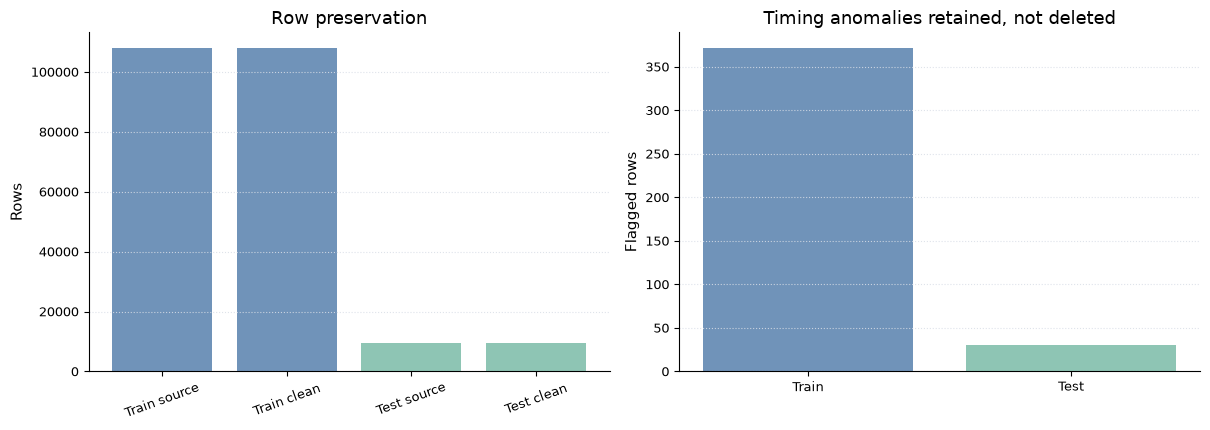

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(12.2, 4.4))

axes[0].bar(
    ["Train source", "Train clean", "Test source", "Test clean"],
    [len(train_source), len(train), len(test_source), len(test)],
    color=[YEAR_COLORS[2016], YEAR_COLORS[2016], YEAR_COLORS[2017], YEAR_COLORS[2017]],
    alpha=0.8,
)
axes[0].set_ylabel("Rows")
axes[0].set_title("Row preservation")
axes[0].tick_params(axis="x", rotation=20)

anomaly_counts = [int(train["timing_anomaly"].sum()), int(test["timing_anomaly"].sum())]
axes[1].bar(["Train", "Test"], anomaly_counts, color=[YEAR_COLORS[2016], YEAR_COLORS[2017]], alpha=0.8)
axes[1].set_ylabel("Flagged rows")
axes[1].set_title("Timing anomalies retained, not deleted")

for ax in axes:
    clean_axis(ax, "y")
plt.tight_layout()
plt.show()


## 6. Prediction-time boundary

`STATUS` remains in the cleaned table for provenance, but it is **not** a valid pre-departure predictor. Cleaning must not silently turn post-outcome information into a feature.

In [7]:
prediction_contract = pd.DataFrame([
    ["Observation unit", "one scheduled flight", "CORE"],
    ["Prediction moment", "before scheduled departure", "CORE"],
    ["Target", "delay minutes", "CORE"],
    ["STATUS", "post/realized status", "EXCLUDE — leakage risk"],
    ["scheduled_interval_min", "STA − STD schedule interval", "EDA / candidate feature"],
    ["Observed delay tier", "derived from target", "EDA ONLY"],
    ["Awkward-hour flag", "target-derived in route atlas", "EDA ONLY"],
])
prediction_contract.columns = ["item", "meaning", "status"]
display(prediction_contract)


,item,meaning,status
0,Observation unit,one scheduled flight,CORE
1,Prediction moment,before scheduled departure,CORE
2,Target,delay minutes,CORE
3,STATUS,post/realized status,EXCLUDE — leakage risk
4,scheduled_interval_min,STA − STD schedule interval,EDA / candidate feature
5,Observed delay tier,derived from target,EDA ONLY
6,Awkward-hour flag,target-derived in route atlas,EDA ONLY


# Part II — Exploratory Data Analysis

The EDA is intentionally question-driven. Complex views are used only when they reveal structure that simpler views suppress. Each section states the interpretation boundary so descriptive target information does not leak into later predictive features.

## 7. Prediction contract + support audit

In [8]:
contract = pd.Series({
    "Observation unit": "one scheduled flight",
    "Prediction moment": "before scheduled departure",
    "Target": "flight-delay duration (min)",
    "Primary task": "regression",
    "Primary metric": "RMSE",
    "Train rows": len(train),
    "Test rows": len(test),
    "Train start": train["STD"].min().date(),
    "Train end": train["STD"].max().date(),
    "Test start": test["STD"].min().date(),
    "Test end": test["STD"].max().date(),
})
display(contract.to_frame("value"))

cardinality = pd.DataFrame({
    "feature": ["DEPSTN", "ARRSTN", "FLTID", "AC", "route"],
    "Train unique": [train[c].nunique(dropna=True) for c in ["DEPSTN", "ARRSTN", "FLTID", "AC", "route"]],
    "Test unique": [test[c].nunique(dropna=True) for c in ["DEPSTN", "ARRSTN", "FLTID", "AC", "route"]],
})
display(cardinality)


,value
Observation unit,one scheduled flight
Prediction moment,before scheduled departure
Target,flight-delay duration (min)
Primary task,regression
Primary metric,RMSE
Train rows,107833
Test rows,9333
Train start,2016-01-01
Train end,2018-12-31
Test start,2016-05-01


,feature,Train unique,Test unique
0,DEPSTN,132,82
1,ARRSTN,128,84
2,FLTID,1861,700
3,AC,68,44
4,route,741,351


## 8. Target geometry — central mass and upper tail

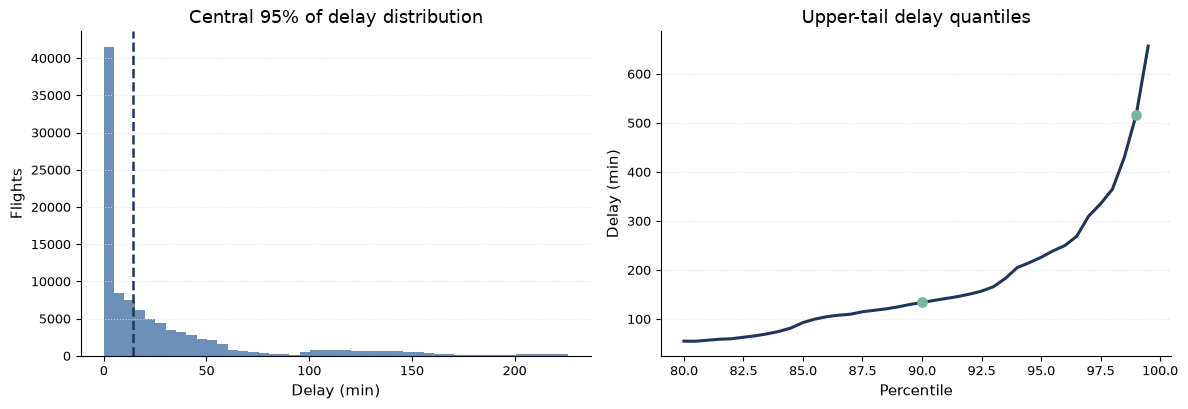

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))

central_cap = train["target"].quantile(0.95)
axes[0].hist(
    train.loc[train["target"] <= central_cap, "target"],
    bins=45, color=YEAR_COLORS[2016], alpha=0.82,
)
axes[0].axvline(train["target"].median(), color=AGG_COLOR, linestyle="--", linewidth=1.8)
axes[0].set_title("Central 95% of delay distribution")
axes[0].set_xlabel("Delay (min)")
axes[0].set_ylabel("Flights")

qs = np.linspace(0.80, 0.995, 40)
qvals = train["target"].quantile(qs)
axes[1].plot(qs * 100, qvals.values, color=AGG_COLOR, linewidth=2.2)
axes[1].scatter([90, 99], train["target"].quantile([0.90, 0.99]), s=45, color=YEAR_COLORS[2017], zorder=3)
axes[1].set_title("Upper-tail delay quantiles")
axes[1].set_xlabel("Percentile")
axes[1].set_ylabel("Delay (min)")

for ax in axes:
    ax.grid(axis="y", linestyle=":", color=GRID_COLOR, alpha=0.9)
    ax.spines[["top", "right"]].set_visible(False)

plt.tight_layout()
plt.show()

The target is strongly right-skewed. 

## 9. Long-term drift — median and P90 across observed years

,n,median,p90
year,,,
2016,28201,9.000,81.000
2017,29263,15.000,139.000
2018,31003,18.000,160.000


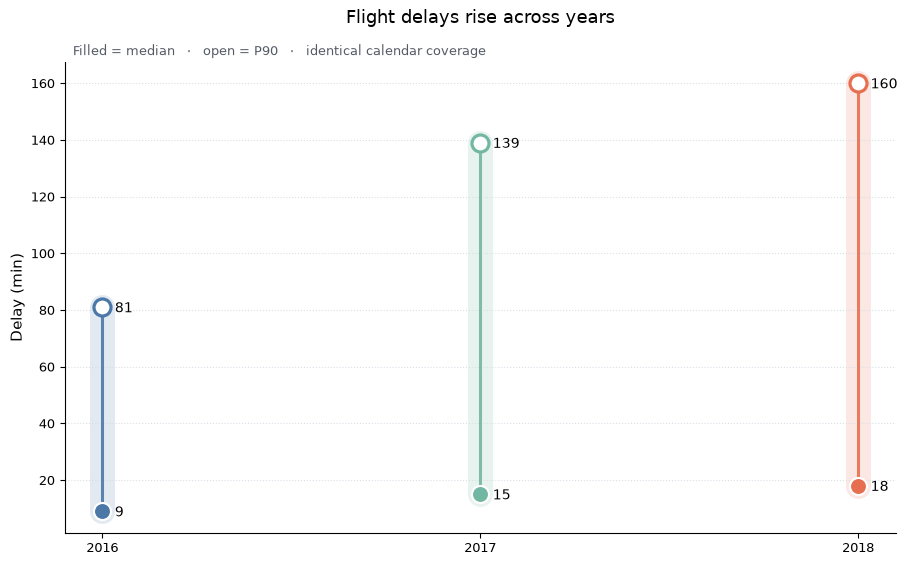

In [10]:
year_profile = (
    train.loc[train["month"].isin(COMPARABLE_MONTHS)]
    .groupby("year")["target"]
    .agg(n="size", median="median", p90=lambda x: x.quantile(0.90))
)

display(year_profile)

fig, ax = plt.subplots(figsize=(9.6, 6.4))
years = year_profile.index.to_list()
x_positions = np.arange(len(years))

for x, year in zip(x_positions, years):
    row = year_profile.loc[year]
    median, p90 = row["median"], row["p90"]
    color = YEAR_COLORS.get(year, AGG_COLOR)

    ax.plot([x, x], [median, p90], color=color, linewidth=18, alpha=0.16, solid_capstyle="round", zorder=1)
    ax.plot([x, x], [median, p90], color=color, linewidth=2.2, alpha=0.90, zorder=2)
    ax.scatter(x, median, s=150, color=color, edgecolor="white", linewidth=1.5, zorder=4)
    ax.scatter(x, p90, s=150, facecolor="white", edgecolor=color, linewidth=2.3, zorder=4)
    ax.annotate(f"{median:.0f}", (x, median), xytext=(9, -1), textcoords="offset points", va="center")
    ax.annotate(f"{p90:.0f}", (x, p90), xytext=(9, -1), textcoords="offset points", va="center")

ax.set_xticks(x_positions)
ax.set_xticklabels(years)
ax.set_ylabel("Delay (min)")
ax.set_title("Flight delays rise across years", pad=28)
ax.text(0.01, 1.008, "Filled = median   ·   open = P90   ·   identical calendar coverage", transform=ax.transAxes, ha="left", va="bottom", fontsize=9, color="#555B66")
ax.grid(axis="y", linestyle=":", color=GRID_COLOR)
ax.spines[["top", "right"]].set_visible(False)
plt.tight_layout(rect=[0.02, 0.02, 0.98, 0.92])
plt.show()

## 10. Recurring temporal delay structure

In [11]:
def raw_profile(df, group_col):
    pivot = df.groupby([group_col, "year"])["target"].median().unstack("year").sort_index()
    return pivot, pivot.median(axis=1, skipna=True)

cycle_data = train.loc[~train["year_month"].isin(INCOMPLETE_BLOCKS)].copy()
monthly_pivot, monthly_aggregate = raw_profile(cycle_data, "month")
weekly_pivot, weekly_aggregate = raw_profile(train, "weekday_num")
departure_pivot, departure_aggregate = raw_profile(train, "departure_hour")
arrival_pivot, arrival_aggregate = raw_profile(train, "arrival_hour")

season_data = train.loc[train["month"].isin(COMPARABLE_MONTHS)].copy()
seasonal_pivot, seasonal_aggregate = raw_profile(season_data, "season")
seasonal_pivot = seasonal_pivot.reindex(SEASON_ORDER)
seasonal_aggregate = seasonal_aggregate.reindex(SEASON_ORDER)

daily = (
    train.assign(date=train["STD"].dt.normalize())
    .groupby("date")["target"].median().rename("daily_median").to_frame()
    .reindex(pd.date_range(train["STD"].min().normalize(), train["STD"].max().normalize(), freq="D"))
)
daily.index.name = "date"
daily = daily.reset_index()
daily["year"] = daily["date"].dt.year
daily["year_month"] = daily["date"].dt.to_period("M").astype(str)
daily.loc[daily["year_month"].isin(INCOMPLETE_BLOCKS), "daily_median"] = np.nan
daily["smooth_7d"] = daily.groupby("year")["daily_median"].transform(lambda s: s.rolling(7, center=True, min_periods=3).median())
daily["dayofyear"] = daily["date"].dt.dayofyear

annual_pivot = daily.pivot(index="dayofyear", columns="year", values="smooth_7d")
annual_aggregate = annual_pivot.median(axis=1, skipna=True)

### Recurring (if at all !) temporal structure of flight delay

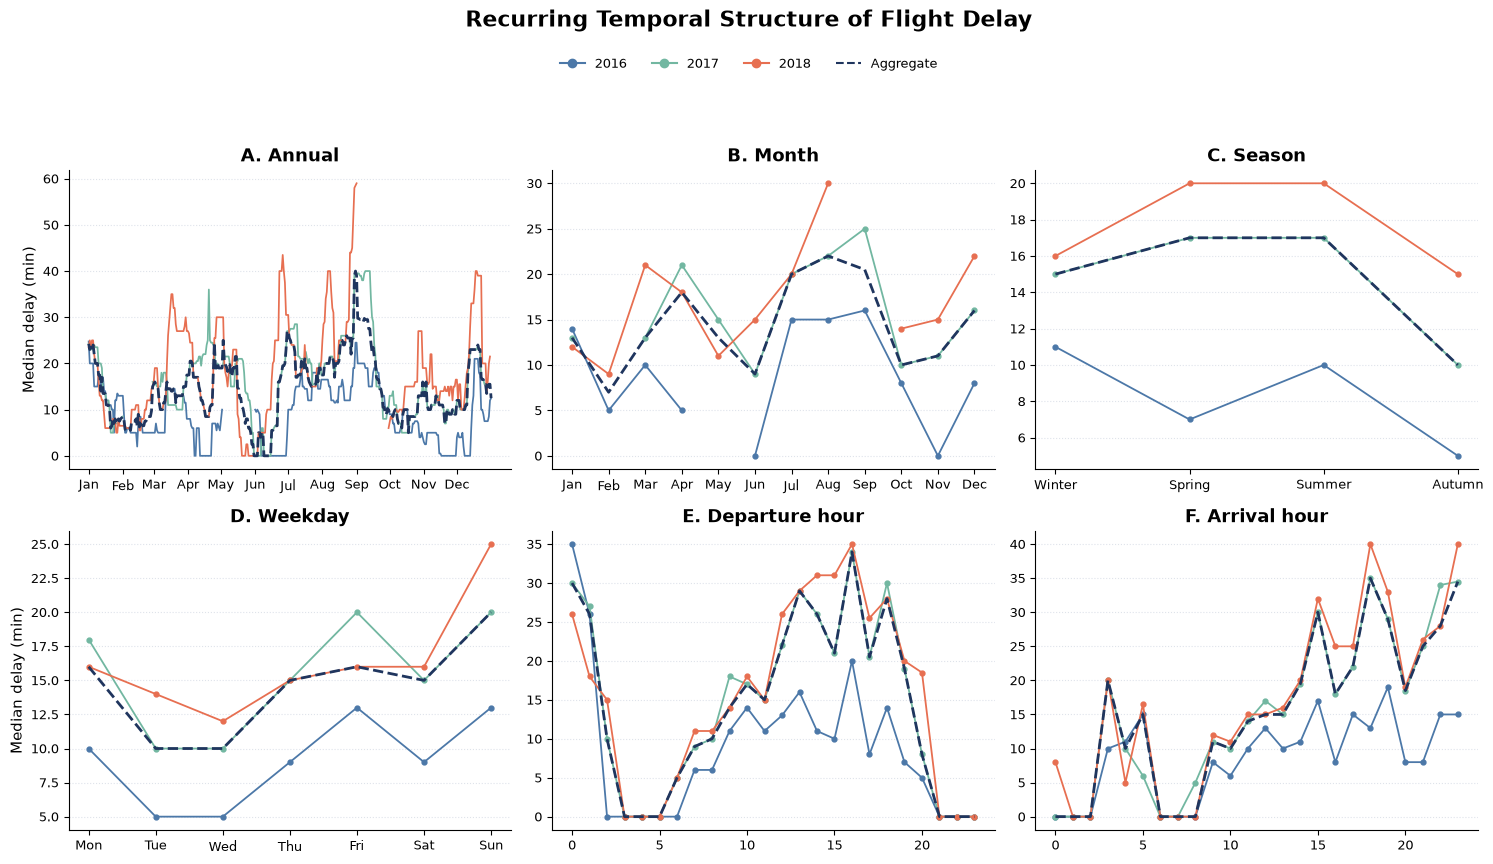

In [12]:
# Rendering of the same six temporal summaries.
fig, axes = plt.subplots(2, 3, figsize=(15.7, 9.0))

# Annual
for year in annual_pivot.columns:
    axes[0,0].plot(annual_pivot.index, annual_pivot[year], color=YEAR_COLORS.get(year, NEUTRAL), linewidth=1.25, label=str(year))
axes[0,0].plot(annual_aggregate.index, annual_aggregate, color=AGG_COLOR, linestyle="--", linewidth=2.0, label="Aggregate")
month_starts = pd.date_range("2019-01-01", "2019-12-01", freq="MS")
axes[0,0].set_xticks(month_starts.dayofyear)
axes[0,0].set_xticklabels([calendar.month_abbr[m] for m in range(1,13)])
axes[0,0].set_title("A. Annual", fontweight="bold")

def alt_profile(ax, pivot, agg, title, labels=None):
    x=np.arange(len(pivot.index))
    for year in pivot.columns:
        ax.plot(x, pivot[year].to_numpy(), marker="o", markersize=3.5, linewidth=1.3, color=YEAR_COLORS.get(year, NEUTRAL))
    ax.plot(x, agg.to_numpy(), linestyle="--", linewidth=2.0, color=AGG_COLOR)
    ax.set_title(title, fontweight="bold")
    if labels is not None:
        ax.set_xticks(x); ax.set_xticklabels(labels)

alt_profile(axes[0,1], monthly_pivot, monthly_aggregate, "B. Month", [calendar.month_abbr[m] for m in monthly_pivot.index])
alt_profile(axes[0,2], seasonal_pivot, seasonal_aggregate, "C. Season", SEASON_ORDER)
alt_profile(axes[1,0], weekly_pivot, weekly_aggregate, "D. Weekday", WEEKDAY_LABELS)
alt_profile(axes[1,1], departure_pivot, departure_aggregate, "E. Departure hour")
alt_profile(axes[1,2], arrival_pivot, arrival_aggregate, "F. Arrival hour")
for ax in axes.ravel():
    clean_axis(ax, "y")
axes[0,0].set_ylabel("Median delay (min)"); axes[1,0].set_ylabel("Median delay (min)")
handles = [plt.Line2D([0],[0], color=YEAR_COLORS[y], marker='o', label=str(y)) for y in [2016,2017,2018]]
handles += [plt.Line2D([0],[0], color=AGG_COLOR, linestyle='--', label='Aggregate')]
fig.suptitle("Recurring Temporal Structure of Flight Delay", fontsize=16, fontweight="bold", y=0.985)
fig.legend(handles=handles, loc="upper center", ncol=4, frameon=False, bbox_to_anchor=(0.5,0.945))
plt.tight_layout(rect=[0.02,0.03,0.98,0.89])
plt.show()


## 11. Repeated month effects after adjusting for each year

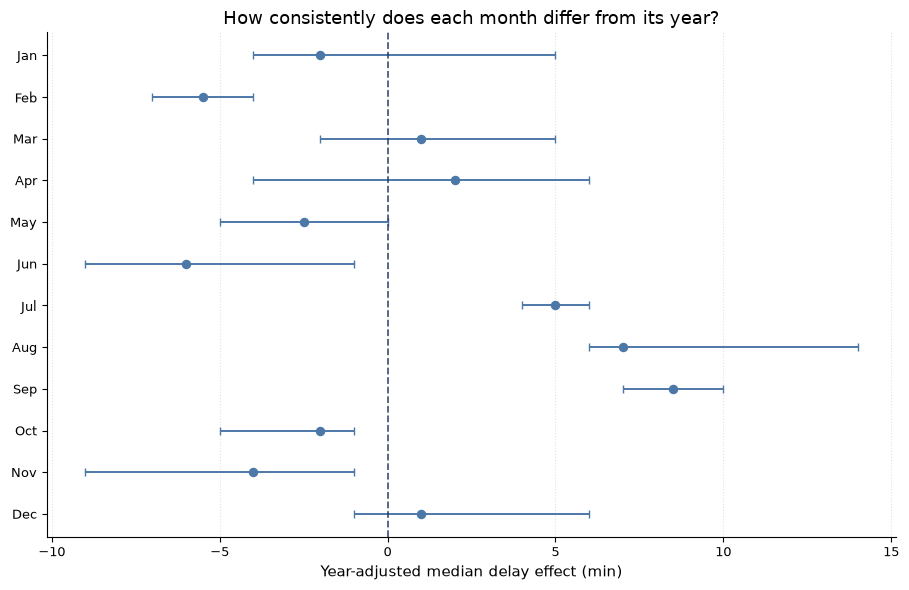

,month_label,years,centre,low,high
0,Jan,3,-2.000,-4.000,5.000
1,Feb,2,-5.500,-7.000,-4.000
2,Mar,3,1.000,-2.000,5.000
3,Apr,3,2.000,-4.000,6.000
4,May,2,-2.500,-5.000,0.000
5,Jun,3,-6.000,-9.000,-1.000
6,Jul,3,5.000,4.000,6.000
7,Aug,3,7.000,6.000,14.000
8,Sep,2,8.500,7.000,10.000
9,Oct,3,-2.000,-5.000,-1.000


In [13]:
month_year = (
    train.loc[~train["year_month"].isin(INCOMPLETE_BLOCKS)]
    .groupby(["year", "month"])["target"]
    .agg(n="size", median_delay="median")
    .reset_index()
)

year_median = (
    train.loc[~train["year_month"].isin(INCOMPLETE_BLOCKS)]
    .groupby("year")["target"]
    .median()
)

month_year["effect_vs_year"] = (
    month_year["median_delay"] - month_year["year"].map(year_median)
)

month_stability = (
    month_year.groupby("month")["effect_vs_year"]
    .agg(years="count", centre="median", low="min", high="max")
    .reindex(range(1, 13))
    .reset_index()
)
month_stability["month_label"] = month_stability["month"].map(lambda m: calendar.month_abbr[int(m)])

fig, ax = plt.subplots(figsize=(9.2, 6.0))
interval_dotplot(
    ax,
    month_stability,
    label_col="month_label",
    point_col="centre",
    low_col="low",
    high_col="high",
    reference=0,
    color=YEAR_COLORS[2016],
    title="How consistently does each month differ from its year?",
    xlabel="Year-adjusted median delay effect (min)",
)
plt.tight_layout()
plt.show()

display(month_stability[["month_label", "years", "centre", "low", "high"]].round(2))


## 12. Nested temporal delay structure — support-aware heatmaps

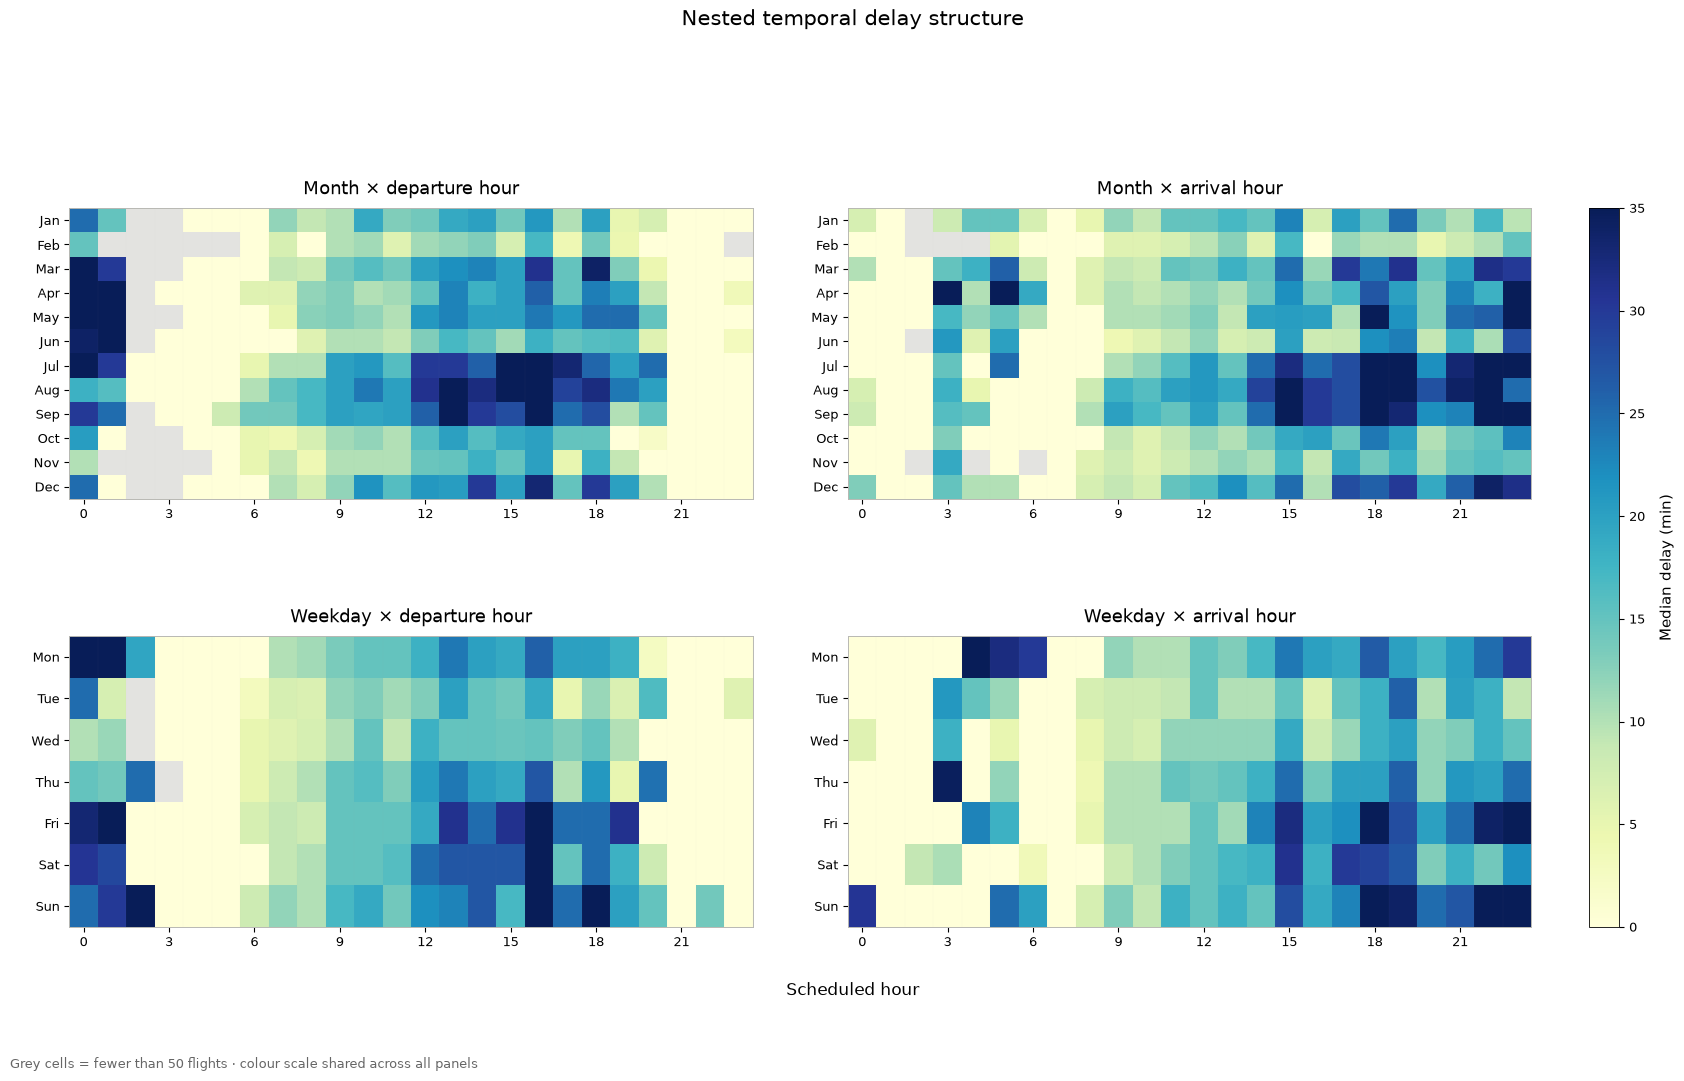

In [14]:

interaction_data = train.loc[~train["year_month"].isin(INCOMPLETE_BLOCKS)].copy()
MIN_CELL_N = 50

def interaction_matrix(row_col, hour_col):
    summary = (
        interaction_data
        .groupby([row_col, hour_col])["target"]
        .agg(n="size", median="median")
        .reset_index()
    )
    median = (
        summary
        .pivot(index=row_col, columns=hour_col, values="median")
        .reindex(columns=range(24))
    )
    count = (
        summary
        .pivot(index=row_col, columns=hour_col, values="n")
        .reindex(columns=range(24))
    )
    return median.mask(count < MIN_CELL_N), count


month_dep, month_dep_n = interaction_matrix("month", "departure_hour")
month_arr, month_arr_n = interaction_matrix("month", "arrival_hour")
week_dep, week_dep_n = interaction_matrix("weekday_num", "departure_hour")
week_arr, week_arr_n = interaction_matrix("weekday_num", "arrival_hour")

matrices = [
    (
        month_dep.reindex(range(1, 13)),
        "Month × departure hour",
        [calendar.month_abbr[m] for m in range(1, 13)],
    ),
    (
        month_arr.reindex(range(1, 13)),
        "Month × arrival hour",
        [calendar.month_abbr[m] for m in range(1, 13)],
    ),
    (
        week_dep.reindex(range(7)),
        "Weekday × departure hour",
        WEEKDAY_LABELS,
    ),
    (
        week_arr.reindex(range(7)),
        "Weekday × arrival hour",
        WEEKDAY_LABELS,
    ),
]

# One common scale keeps all four panels directly comparable.
all_vals = np.concatenate([
    matrix.to_numpy(dtype=float).ravel()
    for matrix, _, _ in matrices
])
all_vals = all_vals[np.isfinite(all_vals)]

vmin, vmax = np.quantile(all_vals, [0.05, 0.95])

# Missing / insufficient-support cells must not look like genuine low delay.
cmap = plt.get_cmap("YlGnBu").copy()
cmap.set_bad("#E3E3E0")

# Reserve a dedicated column for the shared colorbar so it can never
# overlap the right-hand panels.
fig = plt.figure(figsize=(17.2, 10.9), constrained_layout=True)
gs = fig.add_gridspec(
    nrows=2,
    ncols=3,
    width_ratios=[1, 1, 0.045],
    wspace=0.10,
    hspace=0.16,
)

axes = np.array([
    [fig.add_subplot(gs[0, 0]), fig.add_subplot(gs[0, 1])],
    [fig.add_subplot(gs[1, 0]), fig.add_subplot(gs[1, 1])],
])
cax = fig.add_subplot(gs[:, 2])

for panel_idx, (ax, (matrix, title, ylabels)) in enumerate(
    zip(axes.ravel(), matrices)
):
    im = ax.imshow(
        matrix.to_numpy(dtype=float),
        aspect="auto",
        interpolation="nearest",
        cmap=cmap,
        vmin=vmin,
        vmax=vmax,
    )

    ax.set_title(title, pad=10)
    ax.set_xticks(range(0, 24, 3))
    ax.set_xticklabels(range(0, 24, 3))
    ax.set_yticks(range(len(ylabels)))
    ax.set_yticklabels(ylabels)

    # Shared x label at figure level avoids repeated text.
    if panel_idx < 2:
        ax.tick_params(axis="x", labelbottom=True)

    # Light separators aid lookup without turning the heatmap into a grid.
    ax.set_xticks(np.arange(-0.5, 24, 1), minor=True)
    ax.grid(which="minor", axis="x", linewidth=0.25, alpha=0.12)
    ax.tick_params(which="minor", bottom=False)

    for spine in ax.spines.values():
        spine.set_color("#B8B8B3")
        spine.set_linewidth(0.7)

cbar = fig.colorbar(im, cax=cax)
cbar.set_label("Median delay (min)", labelpad=10)
cbar.outline.set_linewidth(0.6)

fig.suptitle(
    "Nested temporal delay structure",
    fontsize=15,
)
fig.supxlabel("Scheduled hour", y=0.088)

fig.text(
    0.01,
    0.022,
    f"Grey cells = fewer than {MIN_CELL_N} flights · colour scale shared across all panels",
    ha="left",
    va="bottom",
    fontsize=9,
    color="#666666",
)

# Geometry QA: reserve a true lower rail for the shared x-label + footer.
fig.get_layout_engine().set(rect=(0.02, 0.130, 0.96, 0.74))

plt.show()


## 13. Supported airport delay profiles

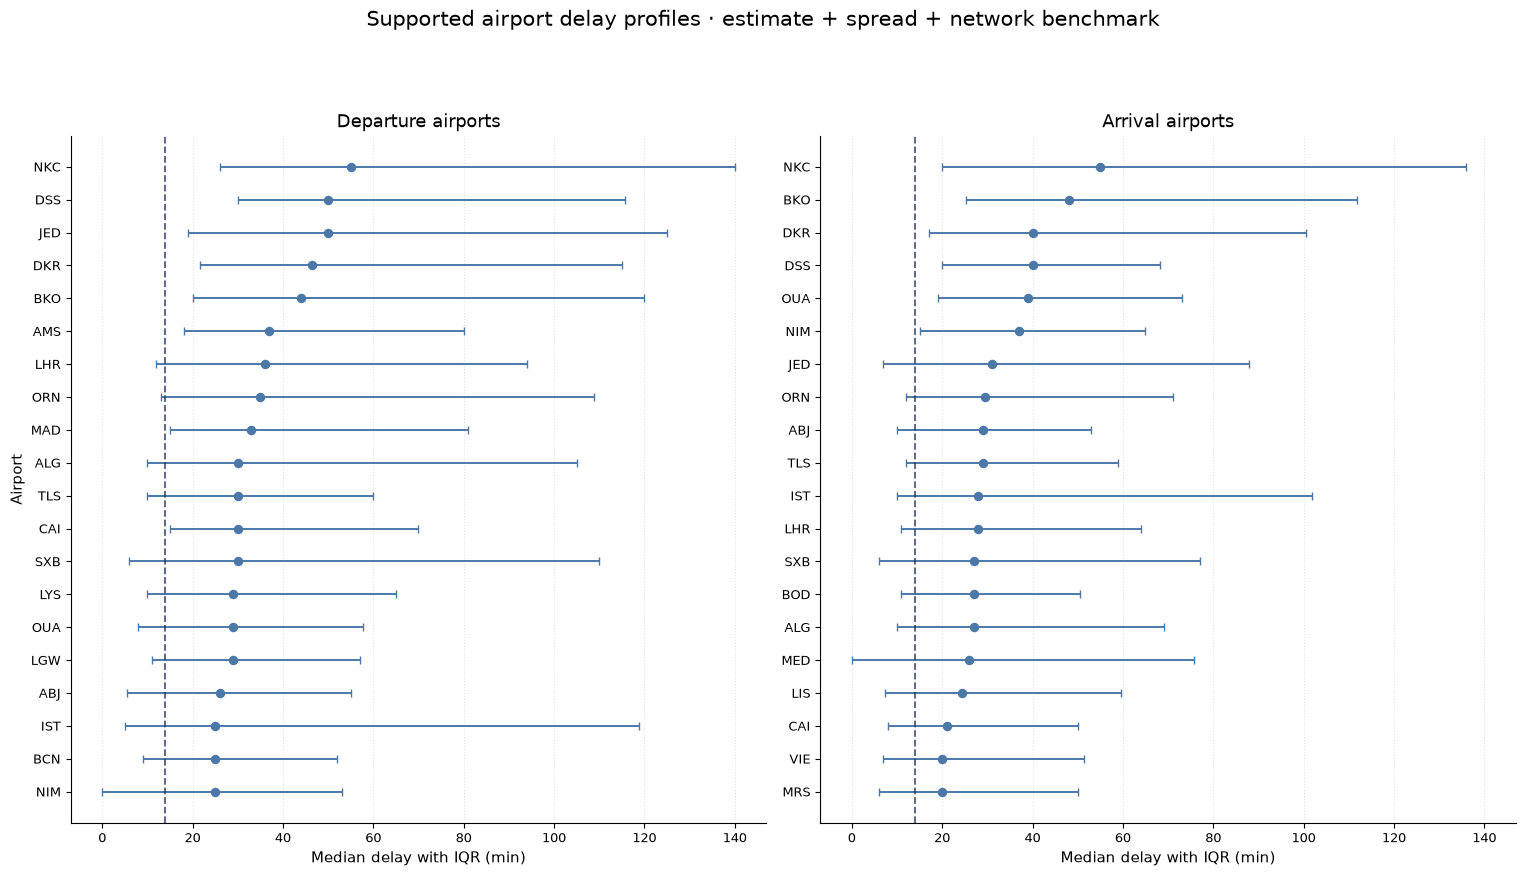

In [15]:
def airport_interval_summary(data, column, min_n=250):
    out = (
        data.groupby(column)["target"]
        .agg(
            n="size",
            q25=lambda x: x.quantile(0.25),
            median="median",
            q75=lambda x: x.quantile(0.75),
            p90=lambda x: x.quantile(0.90),
        )
        .reset_index()
    )
    return out.loc[out["n"] >= min_n].sort_values("median")

network_median = float(train["target"].median())
dep_airport = airport_interval_summary(train, "DEPSTN")
arr_airport = airport_interval_summary(train, "ARRSTN")

fig, axes = plt.subplots(1, 2, figsize=(16.0, 9.2), sharex=True)

interval_dotplot(
    axes[0],
    dep_airport.tail(20),
    "DEPSTN", "median", "q25", "q75",
    reference=network_median,
    color=YEAR_COLORS[2016],
    title="Departure airports",
    xlabel="Median delay with IQR (min)",
    invert=False,
)
interval_dotplot(
    axes[1],
    arr_airport.tail(20),
    "ARRSTN", "median", "q25", "q75",
    reference=network_median,
    color=YEAR_COLORS[2016],
    title="Arrival airports",
    xlabel="Median delay with IQR (min)",
    invert=False,
)
axes[0].set_ylabel("Airport")
fig.suptitle("Supported airport delay profiles · estimate + spread + network benchmark", y=0.982, fontsize=15)
plt.tight_layout(rect=[0.02, 0.035, 0.98, 0.925])
plt.show()


## 14. Route bottleneck atlas — heatmap profile

In [16]:
# Build the shared route-level table once; both route-atlas figures use it.
route_base = train.copy()
route_base["date"] = route_base["DATOP"].dt.normalize()
LONG_INTERVAL_ROUTE_CUT = float(route_base["scheduled_interval_min"].dropna().quantile(0.75))
global_hour_median = route_base.groupby("departure_hour")["target"].median()
awkward_hour_cut = float(global_hour_median.quantile(0.75))
awkward_hours = set(global_hour_median.loc[global_hour_median >= awkward_hour_cut].index)
route_base["awkward_hour_eda"] = route_base["departure_hour"].isin(awkward_hours)
route_base["long_interval"] = route_base["scheduled_interval_min"].ge(LONG_INTERVAL_ROUTE_CUT)


def concentration_hhi(data, group_col, category_col, name):
    counts = data.groupby([group_col, category_col]).size().rename("n").reset_index()
    counts["share"] = counts["n"] / counts.groupby(group_col)["n"].transform("sum")
    return counts.groupby(group_col)["share"].apply(lambda s: float(np.square(s).sum())).rename(name)

route_daily = route_base.groupby(["route", "date"]).size().rename("daily_flights").reset_index()
route_daily_summary = route_daily.groupby("route")["daily_flights"].agg(median_daily_flights="median")
route_year = (
    route_base.loc[~route_base["year_month"].isin(INCOMPLETE_BLOCKS)]
    .groupby(["route", "year"])["target"].median().unstack("year")
)
route_year_range = (route_year.max(axis=1) - route_year.min(axis=1)).rename("year_instability")

route_atlas_all = (
    route_base.groupby("route")["target"]
    .agg(n="size", q25=lambda x:x.quantile(0.25), median_delay="median", q75=lambda x:x.quantile(0.75))
    .join(route_base.groupby("route").agg(
        awkward_hour_share=("awkward_hour_eda","mean"),
        long_interval_share=("long_interval","mean"),
        median_interval=("scheduled_interval_min","median"),
    ))
    .join(route_daily_summary)
    .join(concentration_hhi(route_base,"route","AC","ac_hhi"))
    .join(concentration_hhi(route_base,"route","FLTID","fltid_hhi"))
    .join(route_year_range)
    .reset_index()
)
route_atlas_all["awkward_hour_share"] *= 100
route_atlas_all["long_interval_share"] *= 100
network_median = float(train["target"].median())
route_atlas_all["delay_vs_network"] = route_atlas_all["median_delay"] - network_median
eligible_atlas = route_atlas_all.loc[route_atlas_all["n"] >= 150].copy()
selected_routes = list(dict.fromkeys(
    eligible_atlas.nlargest(10,"n")["route"].tolist()
    + eligible_atlas.nlargest(8,"median_delay")["route"].tolist()
))[:18]
atlas = eligible_atlas.loc[eligible_atlas["route"].isin(selected_routes)].sort_values("delay_vs_network").reset_index(drop=True)


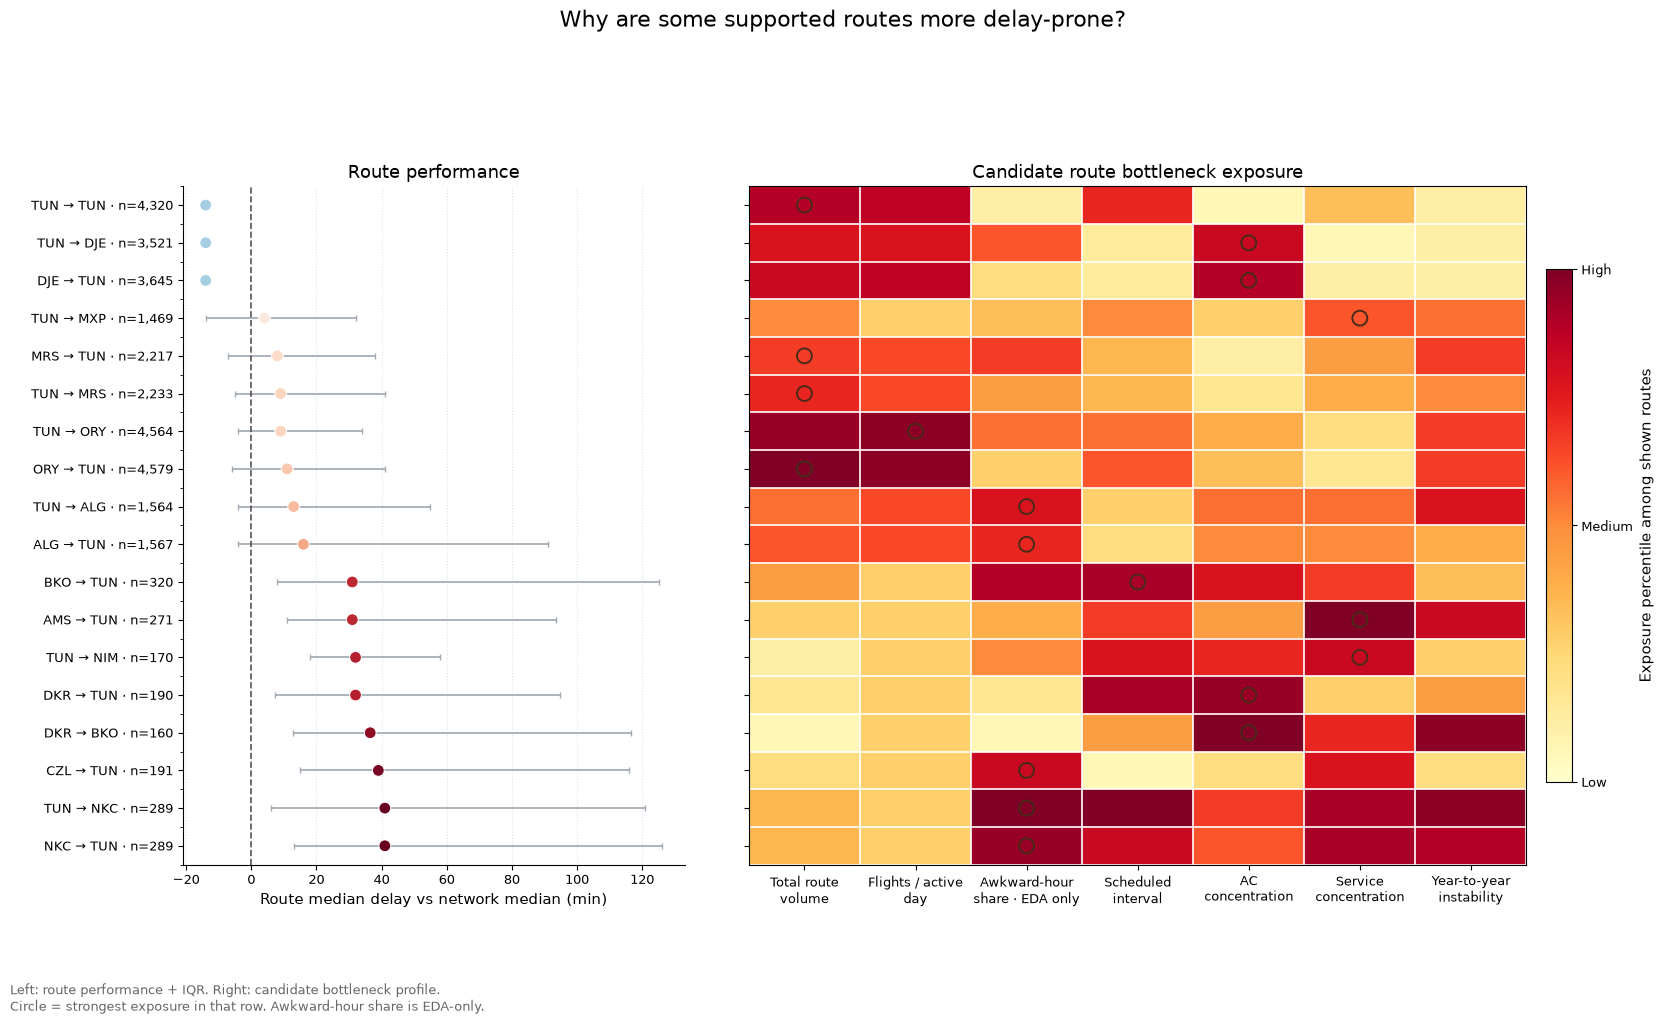

In [17]:
# Heatmap version
heat_cols = {
    "n": "Total route\nvolume",
    "median_daily_flights": "Flights / active\nday",
    "awkward_hour_share": "Awkward-hour\nshare · EDA only",
    "median_interval": "Scheduled\ninterval",
    "ac_hhi": "AC\nconcentration",
    "fltid_hhi": "Service\nconcentration",
    "year_instability": "Year-to-year\ninstability",
}
risk = pd.DataFrame(index=atlas.index)
for col in heat_cols:
    risk[col] = atlas[col].rank(pct=True, method="average").fillna(0)

fig = plt.figure(figsize=(17.0,10.3), constrained_layout=True)
gs=fig.add_gridspec(1,2,width_ratios=[1.0,1.55],wspace=0.07)
ax=fig.add_subplot(gs[0,0]); y=np.arange(len(atlas)); delta=atlas["delay_vs_network"].to_numpy(float)
q25=atlas["q25"].to_numpy(float)-network_median; q75=atlas["q75"].to_numpy(float)-network_median
lim=max(5.0,float(np.quantile(np.abs(delta),0.95))); norm=mcolors.TwoSlopeNorm(vmin=-lim,vcenter=0,vmax=lim); cmap=plt.get_cmap("RdBu_r")
ax.errorbar(delta,y,xerr=np.vstack([delta-q25,q75-delta]),fmt="none",ecolor="#A3AAB2",elinewidth=1.25,capsize=2.5)
ax.scatter(delta,y,s=72,c=[cmap(norm(v)) for v in delta],edgecolor="white",linewidth=0.7,zorder=3)
ax.axvline(0,ls="--",lw=1.2,color="#555555"); ax.set_yticks(y); ax.set_yticklabels([f"{r} · n={int(n):,}" for r,n in zip(atlas.route,atlas.n)],fontsize=9)
ax.set_xlabel("Route median delay vs network median (min)"); ax.set_title("Route performance"); clean_axis(ax,"x")

ax2=fig.add_subplot(gs[0,1],sharey=ax); mat=risk[list(heat_cols)].to_numpy(float)
im=ax2.imshow(mat,aspect="auto",interpolation="nearest",cmap="YlOrRd",vmin=0,vmax=1)
ax2.set_xticks(np.arange(len(heat_cols))); ax2.set_xticklabels(list(heat_cols.values()),fontsize=9); ax2.tick_params(axis="y",labelleft=False)
ax2.set_xticks(np.arange(-0.5,len(heat_cols),1),minor=True); ax2.set_yticks(np.arange(-0.5,len(atlas),1),minor=True); ax2.grid(which="minor",color="white",linewidth=1.2); ax2.tick_params(which="minor",bottom=False,left=False)
ax2.set_title("Candidate route bottleneck exposure")
for ri in range(len(atlas)):
    ci=int(np.nanargmax(mat[ri])); ax2.scatter(ci,ri,s=115,facecolors="none",edgecolors="#4A2A1A",linewidths=1.4)
cbar=fig.colorbar(im,ax=ax2,fraction=0.033,pad=0.025); cbar.set_label("Exposure percentile among shown routes"); cbar.set_ticks([0,.5,1]); cbar.set_ticklabels(["Low","Medium","High"])
fig.suptitle("Why are some supported routes more delay-prone?",fontsize=16)
fig.text(0.01,0.024,"Left: route performance + IQR. Right: candidate bottleneck profile.\nCircle = strongest exposure in that row. Awkward-hour share is EDA-only.",fontsize=9,color="#666666")
fig.get_layout_engine().set(rect=(0.02,0.12,0.96,0.76))
plt.show()


## 15. Route bottleneck atlas — bubble profile

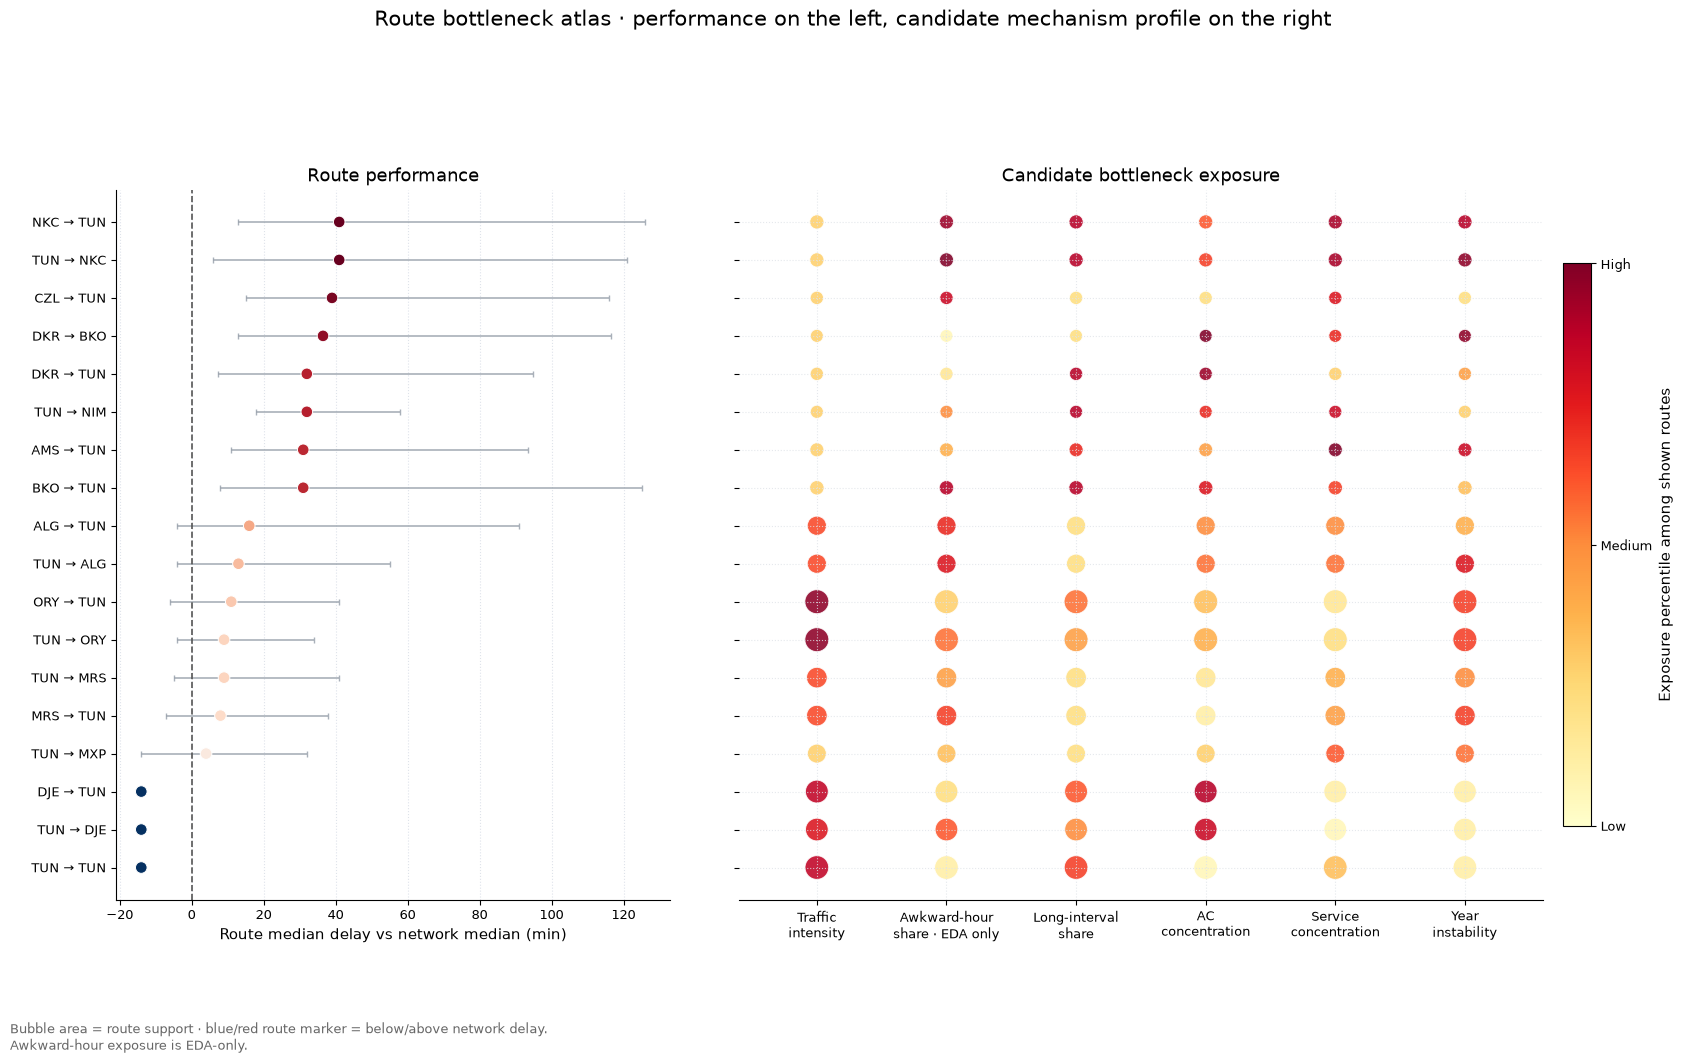

In [18]:
risk_cols = {
    "median_daily_flights": "Traffic\nintensity",
    "awkward_hour_share": "Awkward-hour\nshare · EDA only",
    "long_interval_share": "Long-interval\nshare",
    "ac_hhi": "AC\nconcentration",
    "fltid_hhi": "Service\nconcentration",
    "year_instability": "Year\ninstability",
}
risk_pct=pd.DataFrame(index=atlas.index)
for col in risk_cols:
    risk_pct[col]=atlas[col].rank(pct=True,method="average")

fig=plt.figure(figsize=(17.2,10.7),constrained_layout=True); gs=fig.add_gridspec(1,2,width_ratios=[1.0,1.45],wspace=0.08)
ax=fig.add_subplot(gs[0,0]); y=np.arange(len(atlas)); delta=atlas.delay_vs_network.to_numpy(); q25=atlas.q25.to_numpy()-network_median; q75=atlas.q75.to_numpy()-network_median
norm=mcolors.TwoSlopeNorm(vmin=min(-5,float(np.quantile(delta,.05))),vcenter=0,vmax=max(5,float(np.quantile(delta,.95)))); cmap=plt.get_cmap("RdBu_r")
ax.errorbar(delta,y,xerr=np.vstack([delta-q25,q75-delta]),fmt="none",ecolor="#9AA3AD",elinewidth=1.2,capsize=2.5,alpha=.85)
ax.scatter(delta,y,s=70,c=[cmap(norm(v)) for v in delta],edgecolor="white",linewidth=.7,zorder=3); ax.axvline(0,ls="--",lw=1.2,color="#555")
ax.set_yticks(y); ax.set_yticklabels(atlas.route); ax.set_xlabel("Route median delay vs network median (min)"); ax.set_title("Route performance"); clean_axis(ax,"x")
ax2=fig.add_subplot(gs[0,1],sharey=ax); xs=np.arange(len(risk_cols)); rcmap=plt.get_cmap("YlOrRd"); support=40+260*np.sqrt(atlas.n/atlas.n.max())
for j,col in enumerate(risk_cols):
    vals=risk_pct[col].to_numpy(); ax2.scatter(np.full(len(atlas),j),y,s=support,c=vals,cmap=rcmap,vmin=0,vmax=1,edgecolor="white",linewidth=.7,alpha=.88)
ax2.set_xticks(xs); ax2.set_xticklabels(list(risk_cols.values())); ax2.tick_params(axis="y",labelleft=False); ax2.set_title("Candidate bottleneck exposure"); ax2.set_xlim(-.6,len(risk_cols)-.4); ax2.grid(axis="both",ls=":",color="#DFE3E8",alpha=.8); ax2.spines[["top","right","left"]].set_visible(False)
sm=cm.ScalarMappable(norm=mcolors.Normalize(0,1),cmap=rcmap); sm.set_array([]); cbar=fig.colorbar(sm,ax=ax2,fraction=.035,pad=.025); cbar.set_label("Exposure percentile among shown routes"); cbar.set_ticks([0,.5,1]); cbar.set_ticklabels(["Low","Medium","High"])
fig.suptitle("Route bottleneck atlas · performance on the left, candidate mechanism profile on the right",fontsize=15)
fig.text(.01,.024,"Bubble area = route support · blue/red route marker = below/above network delay.\nAwkward-hour exposure is EDA-only.",fontsize=9,color="#666")
fig.get_layout_engine().set(rect=(.02,.12,.96,.76)); plt.show()


## 16. Service identity / FLTID support

,value
Unique Train FLTID,"1,861.000"
Unique Test FLTID,700.000
Singleton Train services,607.000
Singleton share of Train services (%),32.620
Median Train support,3.000
Test rows with unseen FLTID,67.000
Test rows with unseen FLTID (%),0.720


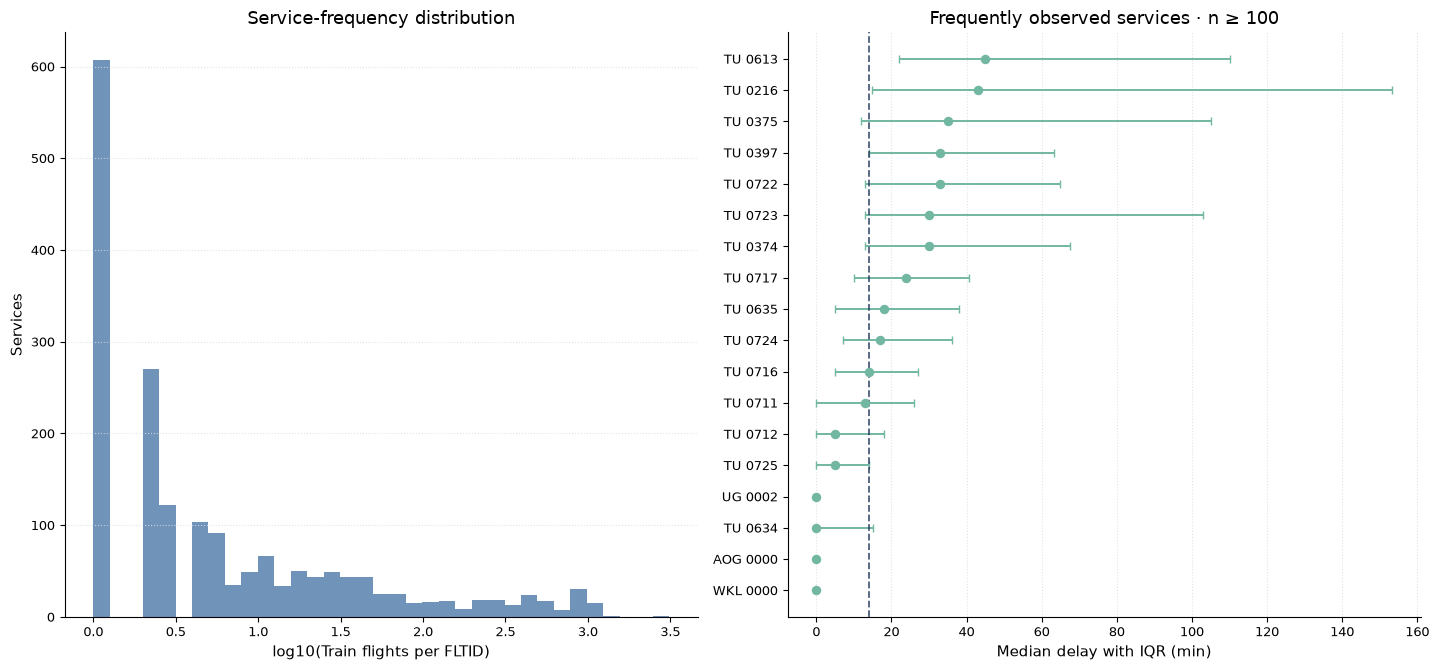

In [19]:
fltid_train = train["FLTID"].astype("string").fillna("MISSING")
fltid_test = test["FLTID"].astype("string").fillna("MISSING")

fltid_counts = fltid_train.value_counts()
fltid_audit = pd.Series({
    "Unique Train FLTID": fltid_train.nunique(),
    "Unique Test FLTID": fltid_test.nunique(),
    "Singleton Train services": int((fltid_counts == 1).sum()),
    "Singleton share of Train services (%)": 100 * float((fltid_counts == 1).mean()),
    "Median Train support": float(fltid_counts.median()),
    "Test rows with unseen FLTID": int((~fltid_test.isin(set(fltid_train))).sum()),
    "Test rows with unseen FLTID (%)": 100 * float((~fltid_test.isin(set(fltid_train))).mean()),
})
display(fltid_audit.to_frame("value").round(2))

service_summary = (
    train.groupby("FLTID")["target"]
    .agg(
        n="size",
        q25=lambda x: x.quantile(0.25),
        median="median",
        q75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
    )
    .reset_index()
)

MIN_SERVICE_N = 100
service_supported = service_summary.loc[service_summary["n"] >= MIN_SERVICE_N].nlargest(18, "n").sort_values("median")

fig, axes = plt.subplots(1, 2, figsize=(14.5, 6.8))

axes[0].hist(np.log10(fltid_counts.values), bins=35, color=YEAR_COLORS[2016], alpha=0.8)
axes[0].set_title("Service-frequency distribution")
axes[0].set_xlabel("log10(Train flights per FLTID)")
axes[0].set_ylabel("Services")
clean_axis(axes[0], "y")

interval_dotplot(
    axes[1],
    service_supported,
    "FLTID", "median", "q25", "q75",
    reference=float(train["target"].median()),
    color=YEAR_COLORS[2017],
    title=f"Frequently observed services · n ≥ {MIN_SERVICE_N}",
    xlabel="Median delay with IQR (min)",
    invert=False,
)

plt.tight_layout()
plt.show()


## 17. Scheduled interval → delay — nonlinear shape with support

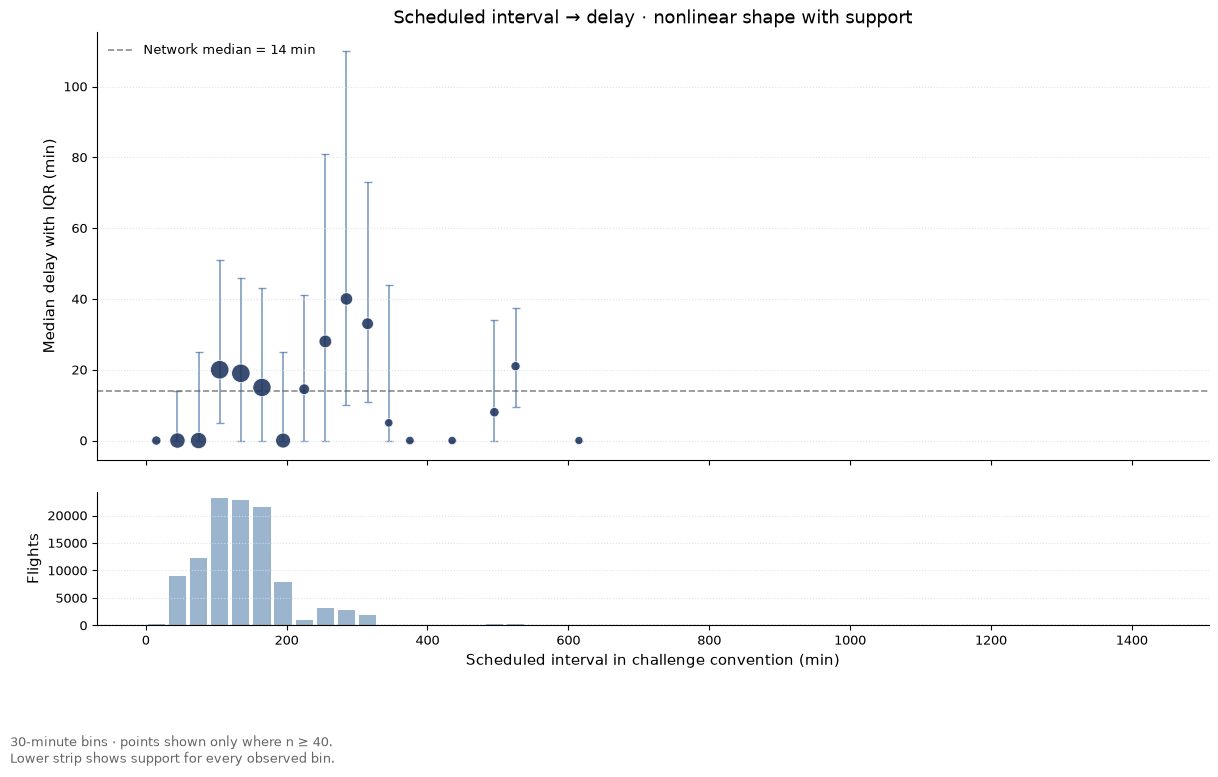

,interval_bin_left,n,median_delay,q25,q75,p90
0,0.000,280,0.000,0.000,0.000,0.000
1,30.000,9031,0.000,0.000,14.000,100.000
2,60.000,12358,0.000,0.000,25.000,105.000
3,90.000,23198,20.000,5.000,51.000,148.000
4,120.000,22898,19.000,0.000,46.000,134.000
5,150.000,21473,15.000,0.000,43.000,141.000
6,180.000,7931,0.000,0.000,25.000,75.000
7,210.000,1032,14.500,0.000,41.200,122.000
8,240.000,3157,28.000,0.000,81.000,193.400
9,270.000,2755,40.000,10.000,110.000,205.000


In [20]:

# -------------------------------------------------------------------
# Support-aware scheduled-interval profile
# -------------------------------------------------------------------
interval_data = train.loc[
    train["scheduled_interval_min"].notna()
    & ~train["timing_anomaly"].fillna(False)
].copy()

# Use fixed 30-minute bins to preserve ordered structure without
# pretending every exact minute value has equal support.
INTERVAL_BIN_WIDTH = 30

interval_data["interval_bin_left"] = (
    np.floor(interval_data["scheduled_interval_min"] / INTERVAL_BIN_WIDTH)
    * INTERVAL_BIN_WIDTH
)

interval_profile = (
    interval_data
    .groupby("interval_bin_left")["target"]
    .agg(
        n="size",
        median_delay="median",
        q25=lambda x: x.quantile(0.25),
        q75=lambda x: x.quantile(0.75),
        p90=lambda x: x.quantile(0.90),
    )
    .reset_index()
)

# Retain bins with enough observations for a stable visual summary.
MIN_INTERVAL_BIN_N = 40
interval_profile["well_supported"] = interval_profile["n"] >= MIN_INTERVAL_BIN_N

fig = plt.figure(figsize=(12.4, 8.9), constrained_layout=True)
gs = fig.add_gridspec(
    nrows=2,
    ncols=1,
    height_ratios=[3.2, 1.0],
    hspace=0.06,
)

ax = fig.add_subplot(gs[0])
ax_support = fig.add_subplot(gs[1], sharex=ax)

show = interval_profile.loc[interval_profile["well_supported"]].copy()

point = show["median_delay"]
low = show["q25"]
high = show["q75"]

# Point area also carries support, but the lower strip gives the exact
# support structure so bubble size does not need to do all the work.
sizes = 28 + 150 * np.sqrt(show["n"] / show["n"].max())

ax.errorbar(
    show["interval_bin_left"] + INTERVAL_BIN_WIDTH / 2,
    point,
    yerr=np.vstack([point - low, high - point]),
    fmt="none",
    ecolor=YEAR_COLORS[2016],
    elinewidth=1.2,
    capsize=3,
    alpha=0.72,
    zorder=1,
)
ax.scatter(
    show["interval_bin_left"] + INTERVAL_BIN_WIDTH / 2,
    point,
    s=sizes,
    color=AGG_COLOR,
    edgecolor="white",
    linewidth=0.6,
    alpha=0.88,
    zorder=3,
)

ax.axhline(
    train["target"].median(),
    linestyle="--",
    linewidth=1.2,
    color="#666666",
    alpha=0.75,
    label=f"Network median = {train['target'].median():.0f} min",
)

ax.set_ylabel("Median delay with IQR (min)")
ax.set_title("Scheduled interval → delay · nonlinear shape with support")
ax.legend(frameon=False, loc="upper left")
clean_axis(ax, "y")
plt.setp(ax.get_xticklabels(), visible=False)

ax_support.bar(
    interval_profile["interval_bin_left"] + INTERVAL_BIN_WIDTH / 2,
    interval_profile["n"],
    width=INTERVAL_BIN_WIDTH * 0.82,
    color=YEAR_COLORS[2016],
    alpha=0.55,
)
ax_support.axhline(
    MIN_INTERVAL_BIN_N,
    linestyle=":",
    linewidth=1.0,
    color="#777777",
)
ax_support.set_ylabel("Flights")
ax_support.set_xlabel("Scheduled interval in challenge convention (min)")
clean_axis(ax_support, "y")

fig.text(
    0.01,
    0.024,
    f"30-minute bins · points shown only where n ≥ {MIN_INTERVAL_BIN_N}.\nLower strip shows support for every observed bin.",
    ha="left",
    va="bottom",
    fontsize=9,
    color="#666666",
)

# Geometry QA: keep the support-panel xlabel above a separate footer rail.
fig.get_layout_engine().set(rect=(0.02, 0.130, 0.96, 0.75))

plt.show()

display(
    interval_profile[
        ["interval_bin_left", "n", "median_delay", "q25", "q75", "p90"]
    ].round(1)
)
